# 04 — Visualization

Charts built from the cleaned data warehouse analytics. Saved to isuals/.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path

sns.set_theme(style='whitegrid', palette='deep')

# Load verified analytical query outputs
data_file = Path('dashboards/dashboard_data.json')
with open(data_file) as f:
    d = json.load(f)

results = {
    'Q2': {'sample': d['attrition_trend']},
    'Q3': {'sample': d['attrition_by_dept']},
    'Q8': {'sample': d['pay_gap_by_level']},
    'Q12': {'sample': d['high_perf_attrition']},
    'Q13': {'sample': d['exit_reasons']},
    'Q17': {'sample': d['cost_by_dept']},
}

## Annualized attrition rate over time

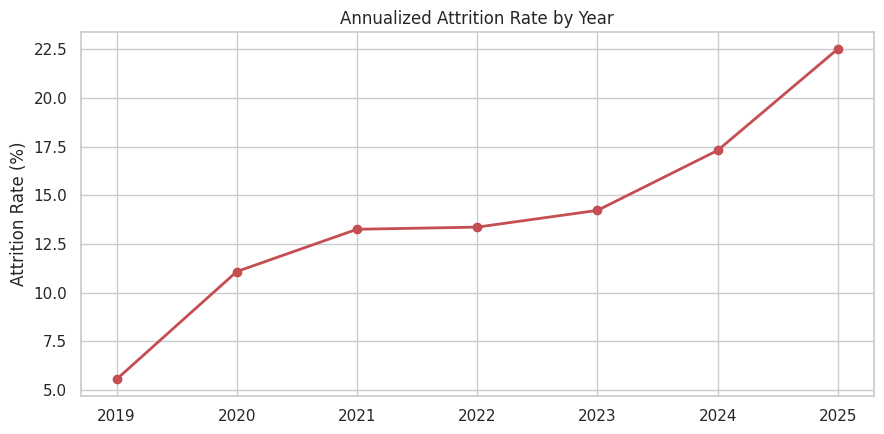

In [2]:
att = pd.DataFrame(results['Q2']['sample'])
fig, ax = plt.subplots(figsize=(9,4.5))
ax.plot(att['yr'], att['attrition_rate_pct'], marker='o', linewidth=2, color=sns.color_palette('deep')[3])
ax.set_title('Annualized Attrition Rate by Year')
ax.set_ylabel('Attrition Rate (%)')
ax.set_xlabel('')
plt.tight_layout()
plt.savefig('visuals/attrition_rate_trend.png', dpi=140)
plt.show()

## Attrition rate by department

/tmp/ipykernel_676/2296980378.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='attrition_rate_pct', y='department', data=dept, ax=ax, palette='flare')


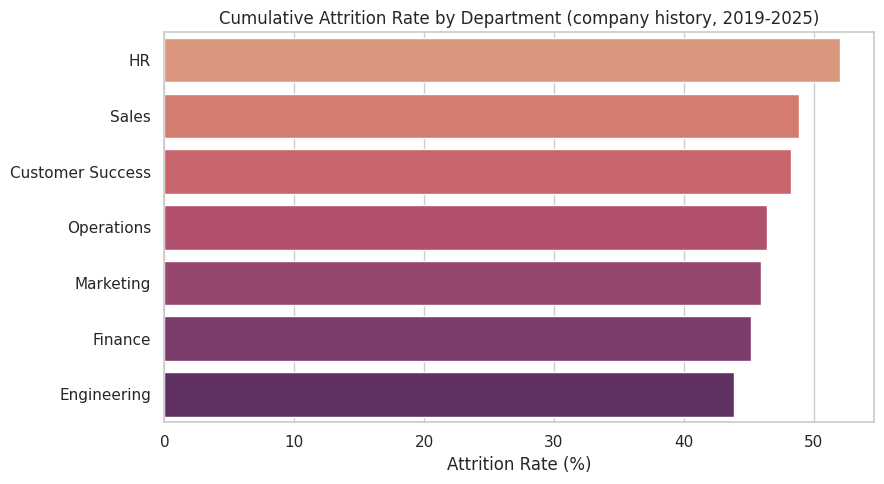

In [3]:
dept = pd.DataFrame(results['Q3']['sample']).sort_values('attrition_rate_pct', ascending=False)
fig, ax = plt.subplots(figsize=(9,5))
sns.barplot(x='attrition_rate_pct', y='department', data=dept, ax=ax, palette='flare')
ax.set_title('Cumulative Attrition Rate by Department (company history, 2019-2025)')
ax.set_xlabel('Attrition Rate (%)')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig('visuals/attrition_by_department.png', dpi=140)
plt.show()

## Gender pay gap by job level

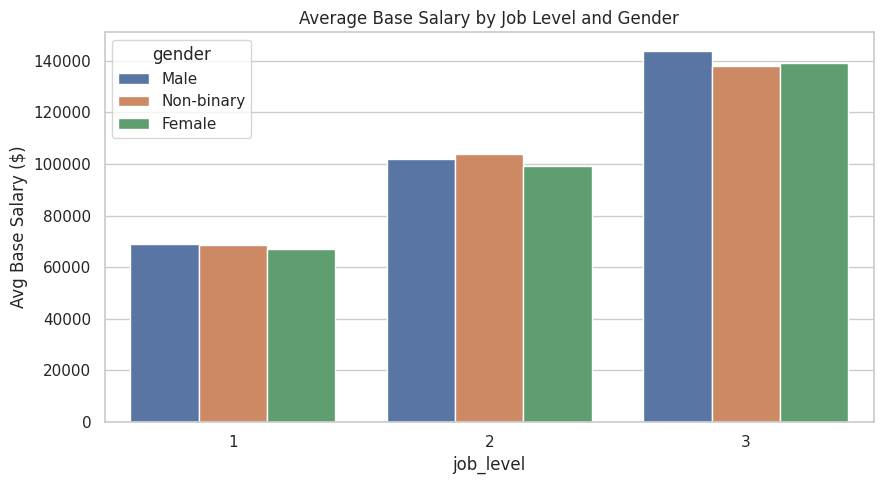

In [4]:
gp = pd.DataFrame(results['Q8']['sample'])
fig, ax = plt.subplots(figsize=(9,5))
sns.barplot(x='job_level', y='avg_base_salary', hue='gender', data=gp, ax=ax, palette='deep')
ax.set_title('Average Base Salary by Job Level and Gender')
ax.set_ylabel('Avg Base Salary ($)')
plt.tight_layout()
plt.savefig('visuals/pay_gap_by_level.png', dpi=140)
plt.show()

## Exit reasons and satisfaction

/tmp/ipykernel_676/2298492571.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='departures', y='reason', data=ex, ax=axes[0], palette='deep')
/tmp/ipykernel_676/2298492571.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='avg_satisfaction', y='reason', data=ex, ax=axes[1], palette='flare')


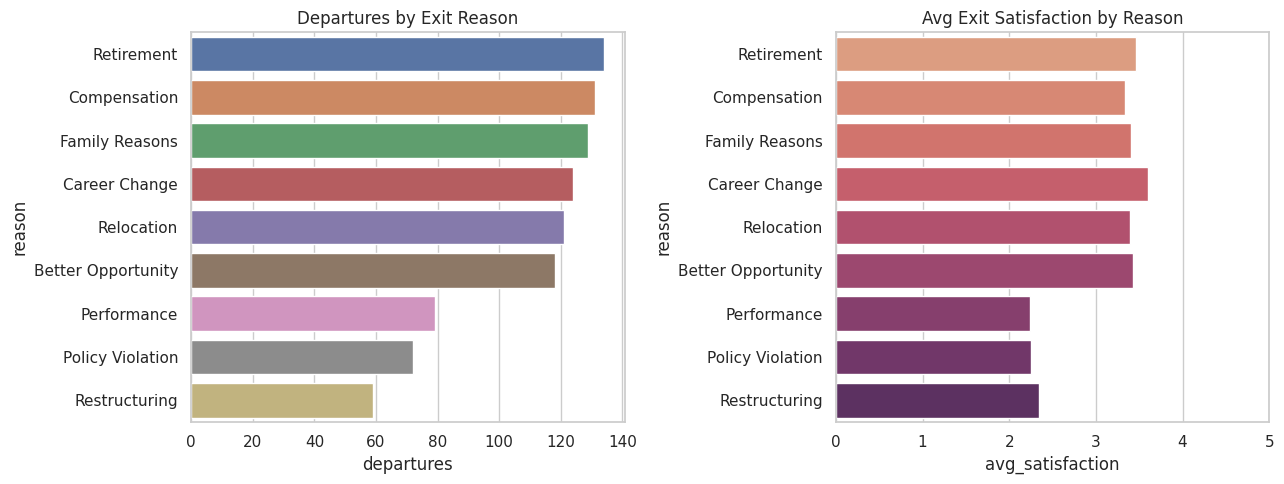

In [5]:
ex = pd.DataFrame(results['Q13']['sample']).sort_values('departures', ascending=False)
fig, axes = plt.subplots(1,2, figsize=(13,5))
sns.barplot(x='departures', y='reason', data=ex, ax=axes[0], palette='deep')
axes[0].set_title('Departures by Exit Reason')
sns.barplot(x='avg_satisfaction', y='reason', data=ex, ax=axes[1], palette='flare')
axes[1].set_title('Avg Exit Satisfaction by Reason')
axes[1].set_xlim(0,5)
plt.tight_layout()
plt.savefig('visuals/exit_reasons.png', dpi=140)
plt.show()

## High performer vs. low performer attrition

/tmp/ipykernel_676/2608400408.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='performance_tier', y='attrition_rate_pct', data=perf, ax=ax, palette='deep')


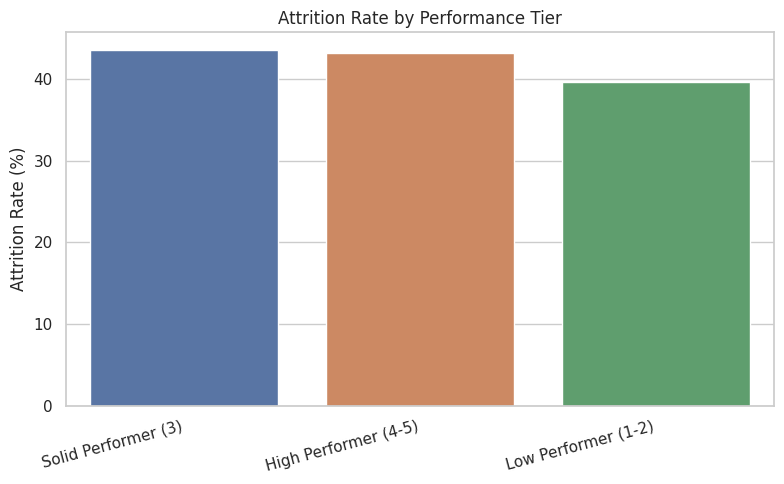

In [6]:
perf = pd.DataFrame(results['Q12']['sample'])
fig, ax = plt.subplots(figsize=(8,5))
sns.barplot(x='performance_tier', y='attrition_rate_pct', data=perf, ax=ax, palette='deep')
ax.set_title('Attrition Rate by Performance Tier')
ax.set_ylabel('Attrition Rate (%)')
ax.set_xlabel('')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.savefig('visuals/attrition_by_performance.png', dpi=140)
plt.show()

## Cost of voluntary attrition by department

/tmp/ipykernel_676/1840403172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='estimated_replacement_cost', y='department', data=cost, ax=ax, palette='rocket')


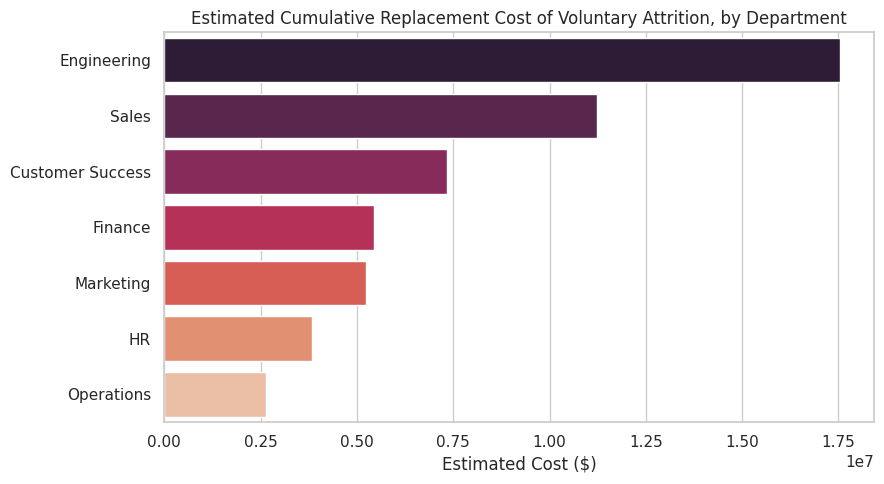

In [7]:
cost = pd.DataFrame(results['Q17']['sample']).sort_values('estimated_replacement_cost', ascending=False)
fig, ax = plt.subplots(figsize=(9,5))
sns.barplot(x='estimated_replacement_cost', y='department', data=cost, ax=ax, palette='rocket')
ax.set_title('Estimated Cumulative Replacement Cost of Voluntary Attrition, by Department')
ax.set_xlabel('Estimated Cost ($)')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig('visuals/attrition_cost_by_department.png', dpi=140)
plt.show()